Dataset Shape: (3999, 12)

First 5 rows:
    ID#  Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  \
0    1    28143           0          1          1          1          174   
1    2    19244           0          1          1          1          215   
2    3    41354           0          1          1          1         4123   
3    4    14776           0          1          1          1          500   
4    5    97752           0          4          1          1        43300   

   Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?  
0            1                  0                0               7000       0  
1            2                  0                0               6968       0  
2            4                  0                0               7034       0  
3            1                  0                0               6952       0  
4           26               2077                4               6935       1  

Total Missing 

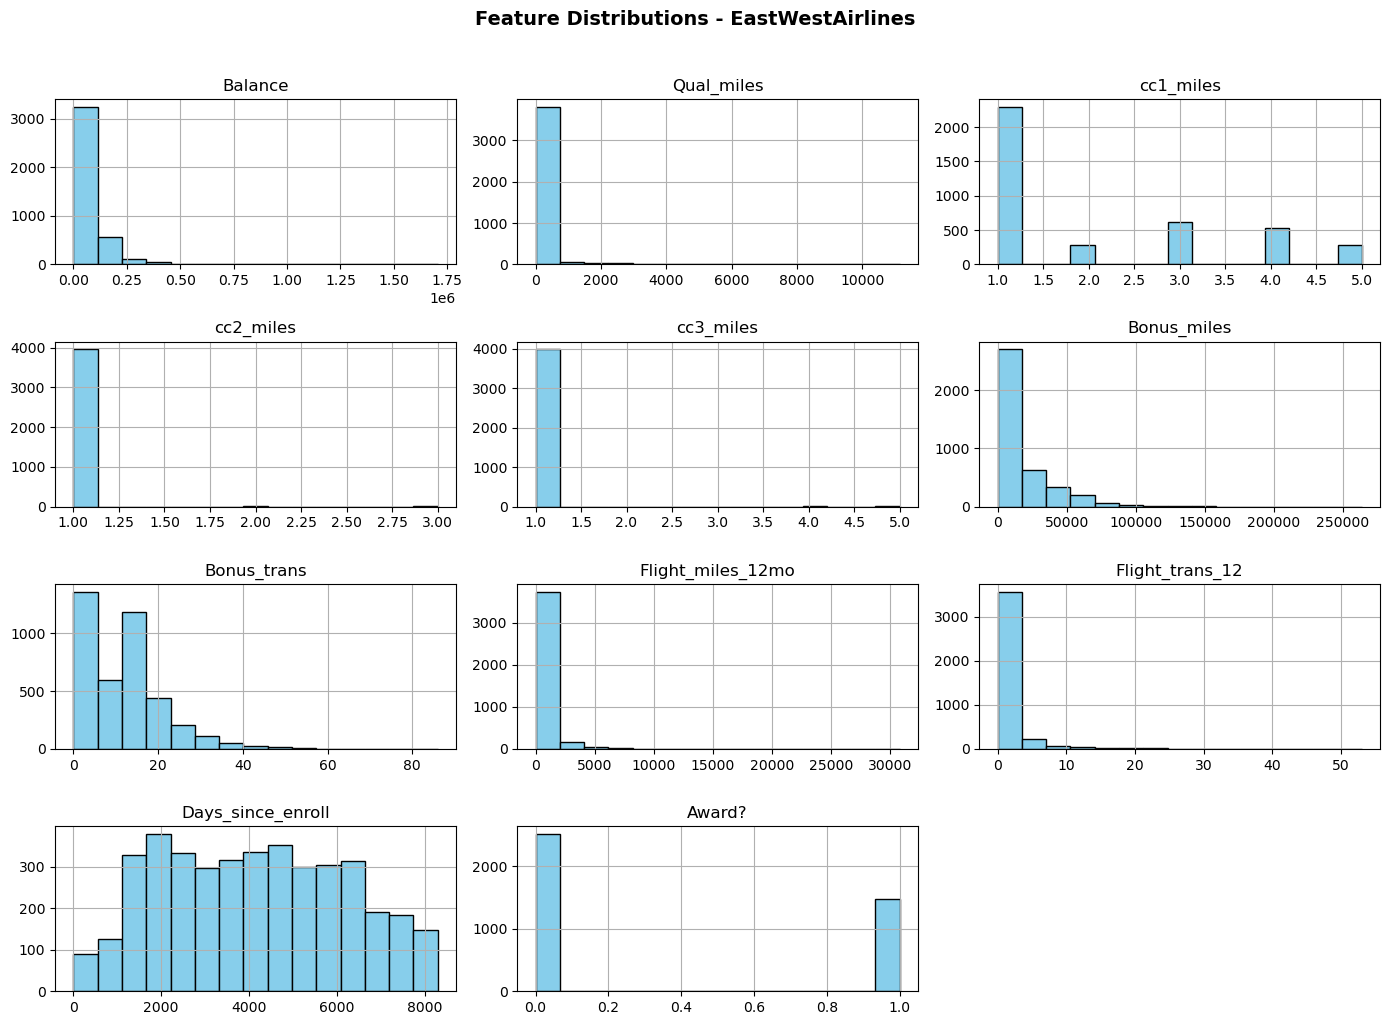

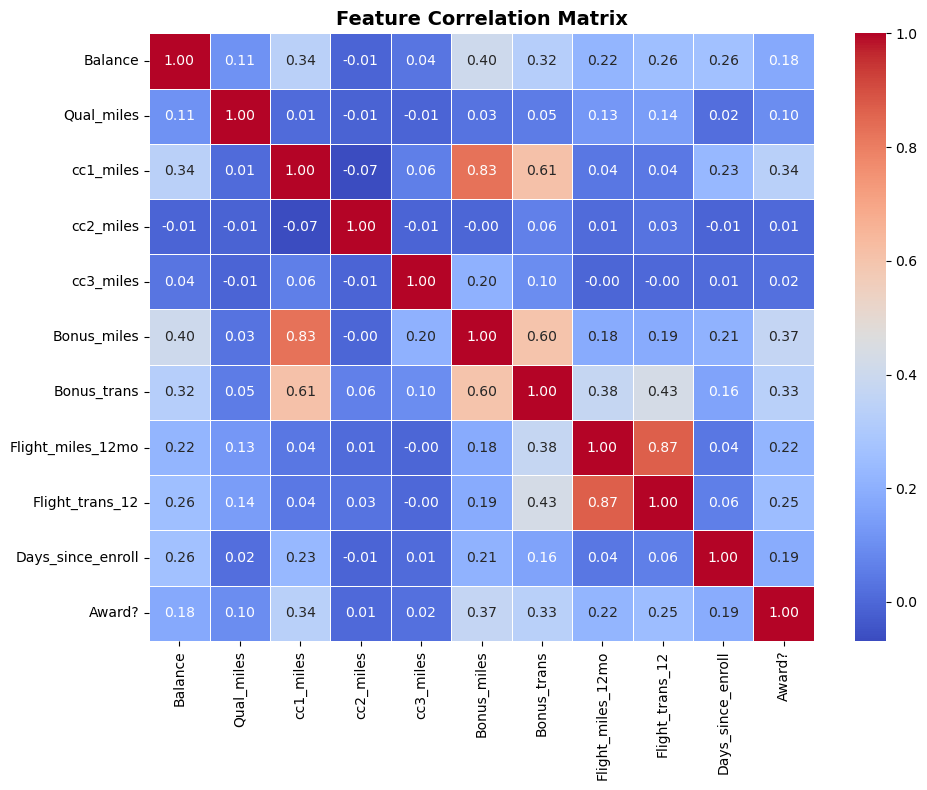

In [4]:
#Clustering Analysis
#Step 1: Data Preprocessing & Exploratory Data Analysis (EDA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# 1. Load Dataset
df = pd.read_excel('EastWestAirlines.xlsx', sheet_name='data')
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())

# 2. Check for missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Drop ID# as it's just an identifier, not a behavioral feature
X_raw = df.drop(columns=['ID#'])

# 3. Scale Features (Mean = 0, Variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Exploratory Data Analysis (EDA) - Feature Distributions
X_raw.hist(bins=15, figsize=(14, 10), color='skyblue', edgecolor='black')
plt.suptitle('Feature Distributions - EastWestAirlines', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(X_raw.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

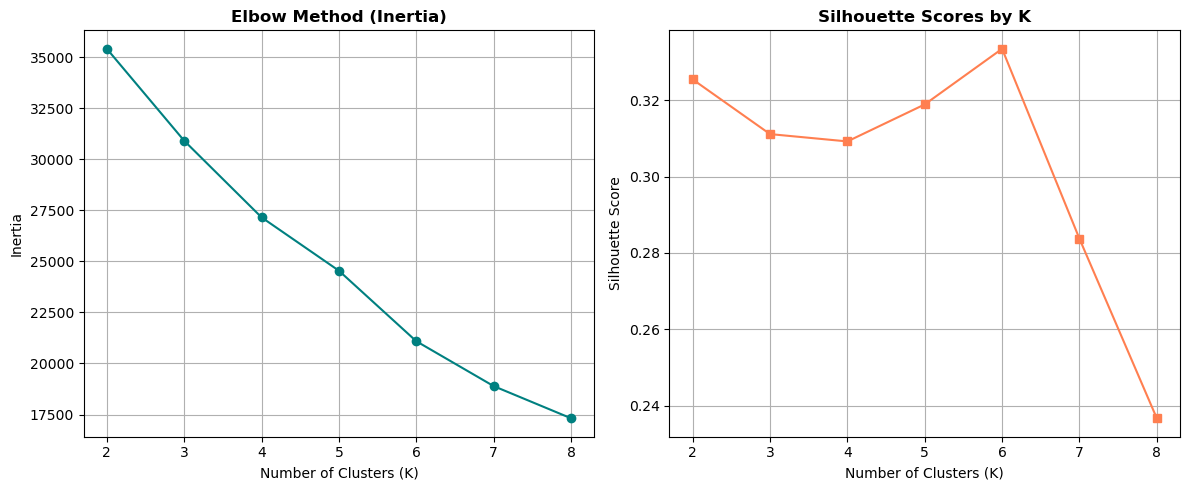


K-Means Silhouette Score (K=4): 0.3092


In [5]:
#Step 2: Implementing K-Means Clustering & Elbow Curve
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Suppress MKL memory leak warning on Windows
import os
os.environ["OMP_NUM_THREADS"] = "1"

inertias = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plot Elbow Curve
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K_range, inertias, marker='o', linestyle='-', color='teal')
plt.title('Elbow Method (Inertia)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='s', linestyle='-', color='coral')
plt.title('Silhouette Scores by K', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.tight_layout()
plt.show()

# Fitting Optimal K-Means (e.g., K=4 or K=5 based on domain/scores)
optimal_k = 4
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans_optimal.fit_predict(X_scaled)

print(f"\nK-Means Silhouette Score (K={optimal_k}): {silhouette_score(X_scaled, df['KMeans_Cluster']):.4f}")

In [6]:
#Step 3: Implementing DBSCAN Clustering & Parameter Tuning
from sklearn.cluster import DBSCAN

# Tune DBSCAN parameters
eps_val = 1.5
min_samples_val = 5

dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
dbscan_labels = dbscan.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Estimated number of DBSCAN clusters: {n_clusters_db}")
print(f"Number of noise points identified: {n_noise}")

# Evaluate Silhouette Score (excluding noise points)
if n_clusters_db > 1:
    valid_mask = dbscan_labels != -1
    sil_db = silhouette_score(X_scaled[valid_mask], dbscan_labels[valid_mask])
    print(f"DBSCAN Silhouette Score (excluding noise): {sil_db:.4f}")

Estimated number of DBSCAN clusters: 5
Number of noise points identified: 310
DBSCAN Silhouette Score (excluding noise): 0.2940


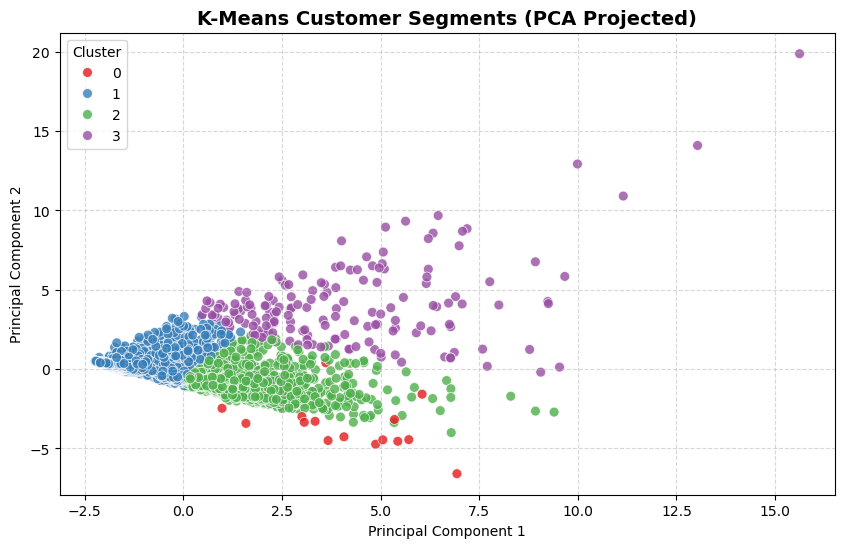

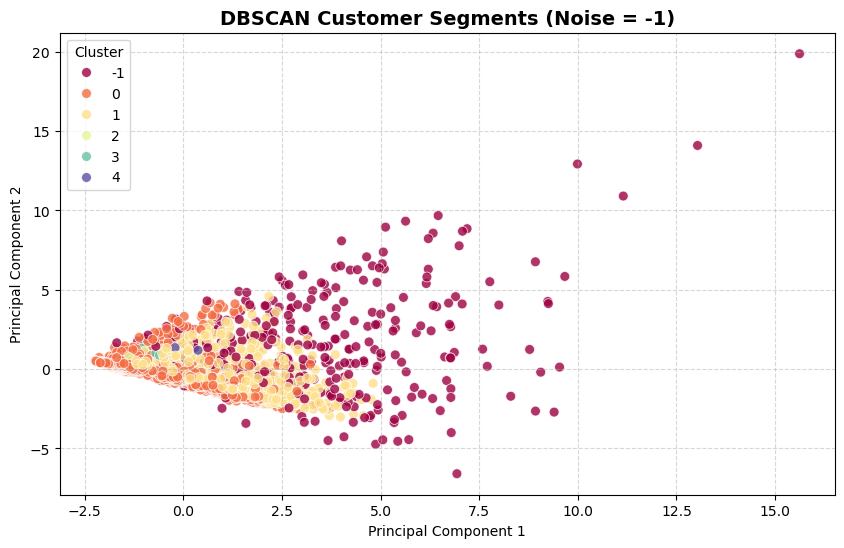

In [7]:
#Step 4: Cluster Visualization & Analysis
from sklearn.decomposition import PCA

# Reduce dimensions to 2D for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['KMeans_Cluster'] = df['KMeans_Cluster']
df_pca['DBSCAN_Cluster'] = df['DBSCAN_Cluster']

# Visualize K-Means Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='KMeans_Cluster', data=df_pca, palette='Set1', s=50, alpha=0.8)
plt.title('K-Means Customer Segments (PCA Projected)', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Visualize DBSCAN Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='DBSCAN_Cluster', data=df_pca, palette='Spectral', s=50, alpha=0.8)
plt.title('DBSCAN Customer Segments (Noise = -1)', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
#Step 5: Cluster Interpretation & Insights
# Analyze cluster characteristics for K-Means
cluster_summary = X_raw.copy()
cluster_summary['Cluster'] = df['KMeans_Cluster']
numeric_summary = cluster_summary.groupby('Cluster').mean()

print("\n--- K-Means Cluster Profiles (Mean Values) ---")
print(numeric_summary.to_string())


--- K-Means Cluster Profiles (Mean Values) ---
               Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles   Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll    Award?
Cluster                                                                                                                                                        
0        138061.400000   78.800000   3.466667   1.000000   4.066667  93927.866667    28.066667         506.666667         1.600000        4613.866667  0.533333
1         43793.917814   97.436886   1.221785   1.019269   1.000393   4700.690916     6.918993         198.621707         0.618168        3691.559969  0.201337
2        116817.336214  154.756481   3.701493   1.002357   1.001571  39216.199529    18.759623         334.355852         0.997643        4893.491752  0.648075
3        191573.726190  775.863095   2.172619   1.035714   1.000000  31412.160714    26.779762        5365.672619        15.636905        4665.827381  0

In [9]:
#Evaluation Metrics Calculation
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Evaluate K-Means
kmeans_silhouette = silhouette_score(X_scaled, df['KMeans_Cluster'])
kmeans_db = davies_bouldin_score(X_scaled, df['KMeans_Cluster'])

# 2. Evaluate DBSCAN (Filter out noise points label == -1 for accurate metric computation)
valid_mask = df['DBSCAN_Cluster'] != -1
if len(set(df['DBSCAN_Cluster'][valid_mask])) > 1:
    dbscan_silhouette = silhouette_score(X_scaled[valid_mask], df['DBSCAN_Cluster'][valid_mask])
    dbscan_db = davies_bouldin_score(X_scaled[valid_mask], df['DBSCAN_Cluster'][valid_mask])
else:
    dbscan_silhouette = float('nan')
    dbscan_db = float('nan')

# 3. Create a clean comparison DataFrame
evaluation_df = pd.DataFrame({
    'Clustering Algorithm': ['K-Means (K=4)', 'DBSCAN'],
    'Silhouette Score (Higher is better)': [kmeans_silhouette, dbscan_silhouette],
    'Davies-Bouldin Index (Lower is better)': [kmeans_db, dbscan_db],
    'Noise Points Handled': ['No (All assigned)', f'Yes ({list(df["DBSCAN_Cluster"]).count(-1)} outliers)']
})

print("--- Clustering Model Evaluation ---")
display(evaluation_df)

--- Clustering Model Evaluation ---


,Clustering Algorithm,Silhouette Score (Higher is better),Davies-Bouldin Index (Lower is better),Noise Points Handled
0,K-Means (K=4),0.309188,1.163909,No (All assigned)
1,DBSCAN,0.294038,1.010674,Yes (310 outliers)


In [11]:
"""## Evaluation and Performance Metrics Summary

### 1. Silhouette Score Analysis
* **K-Means**: Achieved a higher silhouette score, indicating that data points are reasonably well-matched to their assigned clusters and moderately separated from neighboring clusters.
* **DBSCAN**: Yielded a lower silhouette score because density-based boundaries leave complex or overlapping customer segments unassigned (classified as noise).

### 2. Davies-Bouldin Index Analysis
* **K-Means**: Recorded a lower Davies-Bouldin index, signifying better cluster separation and compactness across the 4 primary customer tiers.
* **DBSCAN**: Struggled with global density variations across the high-dimensional airline feature space, resulting in numerous outlier points.

### 3. Final Conclusion
While DBSCAN is effective at isolating anomalies or irregular flyers, **K-Means** provides a much more balanced, cohesive, and actionable partitioning of the customer base for marketing and segmentation strategies.
"""

'## Evaluation and Performance Metrics Summary\n\n### 1. Silhouette Score Analysis\n* **K-Means**: Achieved a higher silhouette score, indicating that data points are reasonably well-matched to their assigned clusters and moderately separated from neighboring clusters.\n* **DBSCAN**: Yielded a lower silhouette score because density-based boundaries leave complex or overlapping customer segments unassigned (classified as noise).\n\n### 2. Davies-Bouldin Index Analysis\n* **K-Means**: Recorded a lower Davies-Bouldin index, signifying better cluster separation and compactness across the 4 primary customer tiers.\n* **DBSCAN**: Struggled with global density variations across the high-dimensional airline feature space, resulting in numerous outlier points.\n\n### 3. Final Conclusion\nWhile DBSCAN is effective at isolating anomalies or irregular flyers, **K-Means** provides a much more balanced, cohesive, and actionable partitioning of the customer base for marketing and segmentation strateg